# 07 — Qiskit Algorithms 0.4.0: variational, eigensolver, amplitude-estimation and time-evolution algorithms

`qiskit-algorithms` is a community-maintained library of quantum algorithms. It is built on the Qiskit **primitives**. A primitive is a standard interface that runs circuits: an *Estimator* computes expectation values, and a *Sampler* returns measured bitstrings. The library provides:

* **Minimum eigensolvers**: `VQE`, `SamplingVQE`, `QAOA`, `NumPyMinimumEigensolver`
* **Eigensolvers**: `VQD`, `NumPyEigensolver`
* **Optimizers**: SciPy wrappers (COBYLA, L-BFGS-B, ...), `SPSA`, NLopt wrappers (CRS, DIRECT-L, ESCH, ISRES, SBPLX) and scikit-quant wrappers (`IMFIL`, `SNOBFIT`, `BOBYQA`)
* **Amplitude amplification and estimation**: `Grover`, `AmplificationProblem`, `IterativeAmplitudeEstimation`, ...
* **Phase estimation**: `PhaseEstimation`, `HamiltonianPhaseEstimation`, ...
* **Time evolution**: `TrotterQRTE`, `VarQITE`/`VarQRTE`, `PVQD`, ...
* **Gradients and QFI** (quantum Fisher information): `ParamShiftEstimatorGradient`, `FiniteDiffEstimatorGradient`, `LinCombQGT`, ...

**Based on** (adapted to version 0.4.0 and the V2 primitives) the `qiskit-algorithms` tutorials:

* An Introduction to Algorithms using Qiskit [[1]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/01_algorithms_introduction.html),
* Advanced VQE Options [[2]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/02_vqe_advanced_options.html),
* Gradient Framework [[3]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/12_gradients_framework.html),
* Variational Quantum Deflation (VQD) Algorithm [[4]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/04_vqd.html),
* Quantum Approximate Optimization Algorithm [[5]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/05_qaoa.html),
* Grover's Algorithm and Amplitude Amplification [[6]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/06_grover.html),
* Quantum Real Time Evolution using Trotterization [[7]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/13_trotterQRTE.html).

The sections on amplitude estimation and phase estimation follow the API reference pages [[21]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.IterativeAmplitudeEstimation.html), [[22]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.PhaseEstimation.html).

**Primitive versions.** Version 0.4.0 accepts only the **V2 primitives** (`BaseEstimatorV2`, `BaseSamplerV2`). All constructor type hints are V2. Qiskit 2.x no longer has the V1 `Estimator` and `Sampler` classes. Here we use the exact reference primitives `StatevectorEstimator` [[8]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator) and `StatevectorSampler` [[9]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler).

Installation:

```bash
pip install qiskit-algorithms nlopt
python -m pip install scikit-quant   # optional optimizers IMFIL / SNOBFIT / BOBYQA
```

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

import qiskit, qiskit_algorithms
from qiskit import QuantumCircuit
from qiskit.circuit.library import real_amplitudes, efficient_su2
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator, StatevectorSampler

from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)  # suppress SciPy sparse-efficiency warnings from statevector evolution

print("qiskit", qiskit.__version__, "| qiskit-algorithms", qiskit_algorithms.__version__)

estimator = StatevectorEstimator(seed=42)   # exact expectation values
sampler = StatevectorSampler(seed=42)       # shot-based sampling from the exact statevector

qiskit 2.5.2 | qiskit-algorithms 0.4.0


## 1. Problem Hamiltonian: the H$_2$ molecule

We use the standard 2-qubit H$_2$ Hamiltonian at bond length 0.735 Å, as in the tutorials [[1]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/01_algorithms_introduction.html), [[2]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/02_vqe_advanced_options.html). It uses the parity mapping with two-qubit reduction and is stored as a `SparsePauliOp`. `NumPyMinimumEigensolver` [[10]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.NumPyMinimumEigensolver.html) diagonalizes it exactly and gives the reference energy in hartree (Ha).

In [2]:
from qiskit_algorithms import NumPyMinimumEigensolver

H2 = SparsePauliOp.from_list([
    ("II", -1.052373245772859),
    ("IZ",  0.39793742484318045),
    ("ZI", -0.39793742484318045),
    ("ZZ", -0.01128010425623538),
    ("XX",  0.18093119978423156),
])

exact = NumPyMinimumEigensolver().compute_minimum_eigenvalue(H2)
E_exact = exact.eigenvalue.real
print(f"Exact ground-state (electronic) energy: {E_exact:.6f} Ha")

Exact ground-state (electronic) energy: -1.857275 Ha


## 2. VQE with the Estimator primitive

The **variational quantum eigensolver (VQE)** [[11]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.VQE.html) minimizes $\langle\psi(\theta)|H|\psi(\theta)\rangle$ over the parameters $\theta$ of an ansatz circuit. The constructor is `VQE(estimator, ansatz, optimizer, callback=...)`. The callback signature is `callback(eval_count, parameters, mean, metadata)`. We use it to record the convergence history [[2]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/02_vqe_advanced_options.html).

The ansatz is the function `real_amplitudes` [[12]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.real_amplitudes). In Qiskit 2.x it replaces the deprecated `RealAmplitudes` class.

In [3]:
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA

ansatz = real_amplitudes(2, reps=2)
print("ansatz parameters:", ansatz.num_parameters)

history = []
def store(eval_count, params, mean, meta):
    history.append(mean)

vqe = VQE(estimator, ansatz, COBYLA(maxiter=200), callback=store,
          initial_point=np.full(ansatz.num_parameters, 0.1))
res = vqe.compute_minimum_eigenvalue(H2)
print(f"VQE energy : {res.eigenvalue:.6f}  (error {abs(res.eigenvalue - E_exact):.2e})")
print("evaluations:", res.cost_function_evals)

ansatz parameters: 6
VQE energy : -1.857275  (error 4.19e-09)
evaluations: 90


## 3. Comparing optimizers

All optimizers [[13]](https://qiskit-community.github.io/qiskit-algorithms/apidocs/qiskit_algorithms.optimizers.html) share the interface `Optimizer.minimize(fun, x0, jac=None, bounds=None)`. So any of them can be used in `VQE`. We compare:

| Optimizer | Type | Source |
|---|---|---|
| `COBYLA` | gradient-free local | SciPy |
| `L_BFGS_B` | gradient-based (VQE supplies finite-difference gradients by default) | SciPy |
| `SPSA` | stochastic perturbation, 2 evaluations per step | qiskit-algorithms |
| `SBPLX` | Subplex (Nelder–Mead on subspaces) | NLopt |
| `IMFIL`, `SNOBFIT` | implicit filtering / branch-and-fit | scikit-quant |

The optional packages are imported in `try` blocks. So the code still runs if `nlopt` or `scikit-quant` is missing. NLopt and scikit-quant optimizers need **bounds**. `real_amplitudes` has no bounds, so we set `ansatz.parameter_bounds` explicitly.

In [4]:
from qiskit_algorithms.optimizers import COBYLA, L_BFGS_B, SPSA

def make_optimizers():
    opts = {
        "COBYLA": COBYLA(maxiter=150),
        "L-BFGS-B": L_BFGS_B(maxiter=50),
        "SPSA": SPSA(maxiter=75, learning_rate=0.1, perturbation=0.1),
    }
    try:
        from qiskit_algorithms.optimizers import SBPLX
        opts["SBPLX (nlopt)"] = SBPLX(max_evals=150)
    except Exception as exc:
        print("nlopt optimizer skipped:", exc)
    for name, cls_name, kw in [("IMFIL (skquant)", "IMFIL", dict(maxiter=150)),
                               ("SNOBFIT (skquant)", "SNOBFIT", dict(maxiter=150, maxfail=20))]:
        try:
            from qiskit_algorithms import optimizers
            opts[name] = getattr(optimizers, cls_name)(**kw)
        except Exception as exc:
            print(f"{name} skipped:", type(exc).__name__, exc)
    return opts

bounded_ansatz = real_amplitudes(2, reps=2)
bounded_ansatz.parameter_bounds = [(-np.pi, np.pi)] * bounded_ansatz.num_parameters
x0 = np.full(bounded_ansatz.num_parameters, 0.1)

histories, finals = {}, {}
for name, opt in make_optimizers().items():
    hist = []
    vqe = VQE(estimator, bounded_ansatz, opt, initial_point=x0,
              callback=lambda n, p, m, md, h=hist: h.append(m))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = vqe.compute_minimum_eigenvalue(H2)
    except Exception as exc:
        print(f"{name} failed at runtime:", type(exc).__name__, exc)
        continue
    histories[name], finals[name] = hist, r.eigenvalue
    print(f"{name:18s} E = {r.eigenvalue: .6f}   |err| = {abs(r.eigenvalue - E_exact):.1e}   evals = {len(hist)}")

SNOBFIT (skquant) skipped: AlgorithmError 'SnobFit is incompatible with NumPy 1.24.0 or above, please install a previous version. See also scikit-quant/scikit-quant#24.'


COBYLA             E = -1.857275   |err| = 4.2e-09   evals = 90


L-BFGS-B           E = -1.857275   |err| = 1.5e-11   evals = 105


SPSA               E = -1.851628   |err| = 5.6e-03   evals = 151


SBPLX (nlopt)      E = -1.857275   |err| = 3.0e-07   evals = 150


IMFIL (skquant)    E = -1.857235   |err| = 4.0e-05   evals = 139


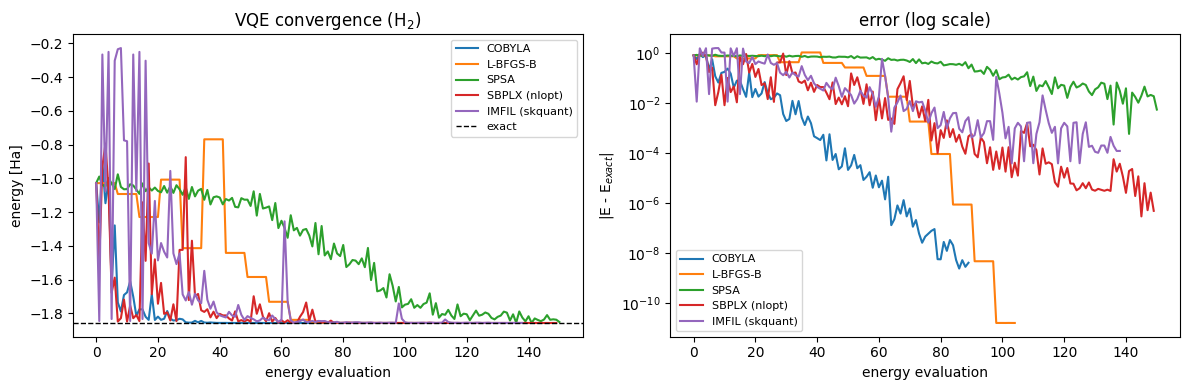

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h, label=name, lw=1.5)
    ax[1].semilogy(np.abs(np.array(h) - E_exact) + 1e-12, label=name, lw=1.5)
ax[0].axhline(E_exact, color="k", ls="--", lw=1, label="exact")
ax[0].set(xlabel="energy evaluation", ylabel="energy [Ha]", title="VQE convergence (H$_2$)")
ax[1].set(xlabel="energy evaluation", ylabel="|E - E$_{exact}$|", title="error (log scale)")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Notes on the results:

* The evaluation count of L-BFGS-B includes the finite-difference gradient evaluations.
* SPSA calls the callback for every energy evaluation, including the perturbed points. So its curve is noisy.
* `IMFIL` and `SNOBFIT` are bound-constrained methods. They search inside the box given by the bounds.

**Note on the installed version.** With the installed NumPy (>= 1.24), the scikit-quant `SNOBFIT` optimizer [[14]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.optimizers.SNOBFIT.html) raises `AlgorithmError: SnobFit is incompatible with NumPy 1.24.0 or above` (scikit-quant/scikit-quant#24). Workaround: the cell above skips it. `IMFIL` from scikit-quant works.

## 4. Gradients: `ParamShiftEstimatorGradient`

The `gradients` module computes $\partial_\theta \langle \psi(\theta)|H|\psi(\theta)\rangle$ with primitives [[3]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/12_gradients_framework.html). The **parameter-shift rule** evaluates the circuit at shifted parameter values, for example $\theta \pm \pi/2$, and combines the results. For gates generated by Pauli rotations, this gives the exact gradient. We compare `ParamShiftEstimatorGradient` [[15]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.gradients.ParamShiftEstimatorGradient.html) with finite differences. Then we pass the gradient to `VQE`, so that L-BFGS-B uses analytic gradients.

In [6]:
from qiskit_algorithms.gradients import ParamShiftEstimatorGradient, FiniteDiffEstimatorGradient

theta = np.random.default_rng(0).uniform(-1, 1, ansatz.num_parameters)
ps_grad = ParamShiftEstimatorGradient(estimator)
fd_grad = FiniteDiffEstimatorGradient(estimator, epsilon=1e-4)

g_ps = ps_grad.run([ansatz], [H2], [theta]).result().gradients[0]
g_fd = fd_grad.run([ansatz], [H2], [theta]).result().gradients[0]
print("parameter shift :", np.round(g_ps, 6))
print("finite diff     :", np.round(g_fd, 6))
print("max |difference|:", np.max(np.abs(g_ps - g_fd)))

parameter shift : [-0.235039  0.076781  0.361109 -0.003585 -0.377605 -0.019507]
finite diff     : [-0.235039  0.076781  0.361109 -0.003585 -0.377605 -0.019507]
max |difference|: 6.310942879395043e-10


In [7]:
hist_grad = []
vqe_g = VQE(estimator, ansatz, L_BFGS_B(maxiter=50), gradient=ps_grad, initial_point=x0,
            callback=lambda n, p, m, md: hist_grad.append(m))
r = vqe_g.compute_minimum_eigenvalue(H2)
print(f"VQE + L-BFGS-B + param-shift gradient: E = {r.eigenvalue:.6f}, energy evals = {len(hist_grad)}")

VQE + L-BFGS-B + param-shift gradient: E = -1.857275, energy evals = 13


## 5. Eigensolvers: excited states with VQD

**Variational quantum deflation (VQD)** [[16]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.VQD.html) finds the $k$ lowest eigenstates. For each new state it adds overlap penalties $\beta \, |\langle \psi_i|\psi(\theta)\rangle|^2$ with the states found before. A **state-fidelity** primitive computes the overlaps. Here this is `ComputeUncompute` [[17]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.state_fidelities.ComputeUncompute.html), built on the sampler. We compare the result with `NumPyEigensolver`, as in the VQD tutorial [[4]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/04_vqd.html).

In [8]:
from qiskit_algorithms import VQD, NumPyEigensolver
from qiskit_algorithms.state_fidelities import ComputeUncompute

k = 3
ref = NumPyEigensolver(k=k).compute_eigenvalues(H2)
print("NumPyEigensolver :", np.round(ref.eigenvalues.real, 6))

fidelity = ComputeUncompute(StatevectorSampler(default_shots=10_000, seed=1))
vqd_ansatz = real_amplitudes(2, reps=3)
vqd_hist = {i: [] for i in range(k)}
def vqd_cb(eval_count, params, value, meta, step):
    vqd_hist[step - 1].append(value)

vqd = VQD(estimator, fidelity, vqd_ansatz, COBYLA(maxiter=300), k=k, betas=[3.0] * k, callback=vqd_cb)
vqd_res = vqd.compute_eigenvalues(H2)
print("VQD              :", np.round(np.real(vqd_res.eigenvalues), 6))

NumPyEigensolver : [-1.857275 -1.244585 -0.882722]


VQD              : [-1.857275 -1.244085 -0.883363]


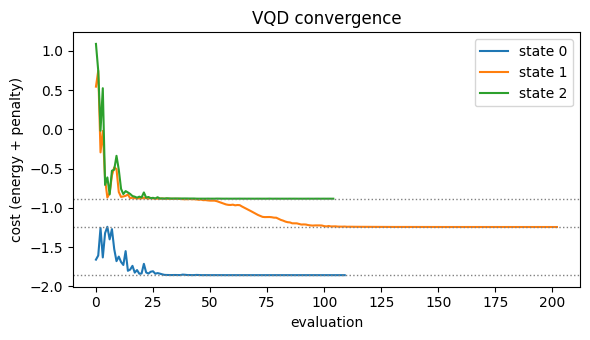

In [9]:
plt.figure(figsize=(6, 3.5))
for i, h in vqd_hist.items():
    plt.plot(h, label=f"state {i}")
for e in ref.eigenvalues.real:
    plt.axhline(e, color="gray", ls=":", lw=1)
plt.xlabel("evaluation"); plt.ylabel("cost (energy + penalty)"); plt.title("VQD convergence")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Sampler-based minimum eigensolvers: QAOA and SamplingVQE

For **diagonal** (classical) Hamiltonians, `QAOA` [[18]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.QAOA.html) and `SamplingVQE` [[19]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.SamplingVQE.html) use a *Sampler*. They return two results:

* the best measured bitstring (`best_measurement`),
* the eigenstate as a quasi-probability distribution.

QAOA (quantum approximate optimization algorithm) uses an ansatz of alternating cost and mixer layers [[5]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/05_qaoa.html). `SamplingVQE` with `aggregation=0.2` minimizes the CVaR (conditional value at risk): the mean of the lowest 20 % of the sampled energies.

We solve MaxCut on a 4-node ring with one chord. The cost Hamiltonian is $H = \sum_{(i,j)\in E} \tfrac12 Z_i Z_j$ (up to a constant).

In [10]:
from qiskit_algorithms import QAOA, SamplingVQE

edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]
n = 4
def zz(i, j):
    s = ["I"] * n; s[n - 1 - i] = "Z"; s[n - 1 - j] = "Z"
    return "".join(s)
H_maxcut = SparsePauliOp.from_list([(zz(i, j), 0.5) for i, j in edges])
print(H_maxcut)

ref_mc = NumPyMinimumEigensolver().compute_minimum_eigenvalue(H_maxcut)
print("exact min energy:", ref_mc.eigenvalue.real)

def cut_size(bitstring):
    x = [int(b) for b in bitstring[::-1]]
    return sum(x[i] != x[j] for i, j in edges)

SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'ZIIZ', 'IZIZ'],
              coeffs=[0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j])
exact min energy: -1.5


In [11]:
qaoa_hist = []
qaoa = QAOA(sampler, COBYLA(maxiter=100), reps=2, initial_point=[0.5, 0.5, 0.5, 0.5],
            callback=lambda n, p, m, md: qaoa_hist.append(m))
qaoa_res = qaoa.compute_minimum_eigenvalue(H_maxcut)
best = qaoa_res.best_measurement
print("QAOA energy (mean)      :", round(qaoa_res.eigenvalue.real, 4))
print("best bitstring           :", best["bitstring"], "cut =", cut_size(best["bitstring"]),
      "value =", best["value"].real)

svqe_hist = []
svqe = SamplingVQE(sampler, real_amplitudes(n, reps=1), COBYLA(maxiter=100), aggregation=0.2,
                   callback=lambda n_, p, m, md: svqe_hist.append(m))
svqe_res = svqe.compute_minimum_eigenvalue(H_maxcut)
print("SamplingVQE best bitstring:", svqe_res.best_measurement["bitstring"],
      "cut =", cut_size(svqe_res.best_measurement["bitstring"]))

QAOA energy (mean)      : -0.7617
best bitstring           : 1010 cut = 4 value = -1.5


SamplingVQE best bitstring: 0101 cut = 4


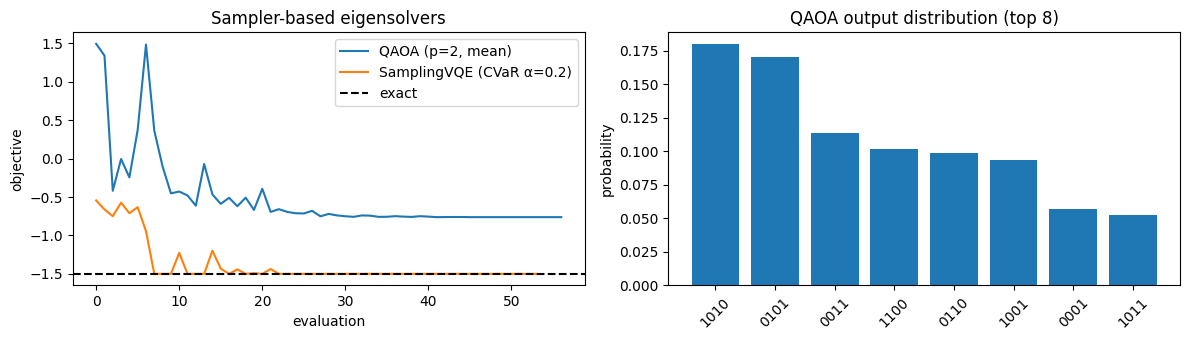

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(qaoa_hist, label="QAOA (p=2, mean)"); ax[0].plot(svqe_hist, label="SamplingVQE (CVaR α=0.2)")
ax[0].axhline(ref_mc.eigenvalue.real, color="k", ls="--", label="exact")
ax[0].set(xlabel="evaluation", ylabel="objective", title="Sampler-based eigensolvers"); ax[0].legend()
dist = qaoa_res.eigenstate
top = sorted(dist.items(), key=lambda kv: -kv[1])[:8]
labels = [format(k_, f"0{n}b") if isinstance(k_, int) else k_ for k_, _ in top]
ax[1].bar(labels, [v for _, v in top]); ax[1].set(title="QAOA output distribution (top 8)", ylabel="probability")
plt.setp(ax[1].get_xticklabels(), rotation=45); plt.tight_layout(); plt.show()

## 7. Grover search with `AmplificationProblem`

An `AmplificationProblem` contains an **oracle** and an `is_good_state` predicate [[6]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/06_grover.html). The oracle is a circuit or a `Statevector` that marks the good states. `Grover` [[20]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.Grover.html) chooses the number of iterations (or tries a list of values) and runs on the sampler.

top measurement : 110
oracle evaluation: True


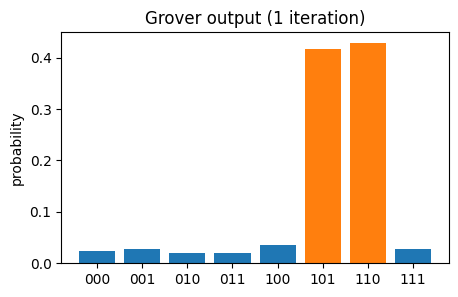

In [13]:
from qiskit_algorithms import Grover, AmplificationProblem

marked = ["101", "110"]
oracle = Statevector.from_label(marked[0]) + Statevector.from_label(marked[1])  # phase oracle from a "good" state
oracle = Statevector(oracle.data / np.linalg.norm(oracle.data))
problem = AmplificationProblem(oracle, is_good_state=marked)

grover = Grover(iterations=1, sampler=sampler)   # optimal for M=2 of N=8
g_res = grover.amplify(problem)
print("top measurement :", g_res.top_measurement)
print("oracle evaluation:", g_res.oracle_evaluation)
probs = dict(sorted(g_res.circuit_results[0].items()))
plt.figure(figsize=(5, 3)); plt.bar(probs.keys(), probs.values(), color=["C1" if k in marked else "C0" for k in probs])
plt.title("Grover output (1 iteration)"); plt.ylabel("probability"); plt.show()

## 8. Amplitude estimation (Iterative QAE)

`IterativeAmplitudeEstimation` [[21]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.IterativeAmplitudeEstimation.html) estimates $a = P(\text{objective qubit} = 1)$ for a state-preparation circuit $\mathcal{A}$. Unlike canonical amplitude estimation, it does not use quantum phase estimation (QPE). We encode a Bernoulli variable with $p = 0.3$ through $R_y(2\arcsin\sqrt p)$.

In [14]:
from qiskit_algorithms import EstimationProblem, IterativeAmplitudeEstimation

p = 0.3
A = QuantumCircuit(1); A.ry(2 * np.arcsin(np.sqrt(p)), 0)
Q = QuantumCircuit(1); Q.ry(2 * 2 * np.arcsin(np.sqrt(p)), 0)  # Grover operator for this 1-qubit problem
est_problem = EstimationProblem(state_preparation=A, objective_qubits=[0], grover_operator=Q)

iae = IterativeAmplitudeEstimation(epsilon_target=0.01, alpha=0.05,
                                   sampler=StatevectorSampler(default_shots=1000, seed=7))
iae_res = iae.estimate(est_problem)
print(f"estimate = {iae_res.estimation:.4f}  (true {p})")
print("95% confidence interval:", np.round(iae_res.confidence_interval, 4))
print("oracle queries:", iae_res.num_oracle_queries)

estimate = 0.3003  (true 0.3)
95% confidence interval: [0.2977 0.3029]
oracle queries: 7000


## 9. Quantum phase estimation

`PhaseEstimation(num_evaluation_qubits, sampler)` [[22]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.PhaseEstimation.html) estimates $\phi$ in $U|\psi\rangle = e^{2\pi i\phi}|\psi\rangle$. We use $U = P(2\pi\cdot 0.375)$ and $|\psi\rangle=|1\rangle$. Three evaluation qubits represent $\phi=0.375 = 0.011_2$ exactly.

In [15]:
from qiskit_algorithms import PhaseEstimation

phi = 0.375
U = QuantumCircuit(1); U.p(2 * np.pi * phi, 0)
psi = QuantumCircuit(1); psi.x(0)

pe = PhaseEstimation(num_evaluation_qubits=3, sampler=sampler)
pe_res = pe.estimate(unitary=U, state_preparation=psi)
print("most likely phase:", pe_res.phase)

most likely phase: 0.375


## 10. Real-time evolution with `TrotterQRTE`

A `TimeEvolutionProblem` holds $H$, the total time and the initial state. `TrotterQRTE` [[23]](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.TrotterQRTE.html) builds a product-formula circuit [[7]](https://qiskit-community.github.io/qiskit-algorithms/tutorials/13_trotterQRTE.html). It can also evaluate `aux_operators` with the estimator at every time step.

We evolve $|00\rangle$ under a 2-qubit Heisenberg-type Hamiltonian with a transverse field. We track $\langle Z_0\rangle$ and compare it with the exact evolution.

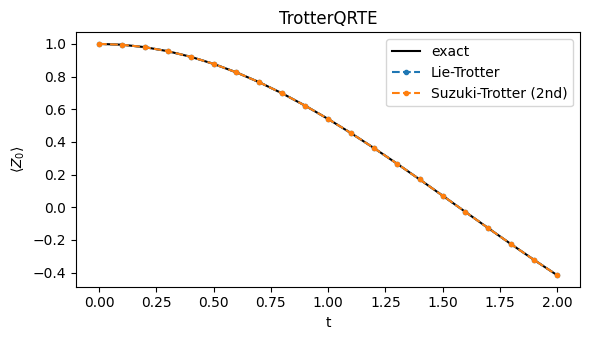

final evolved state circuit depth: 560


In [16]:
from qiskit_algorithms import TimeEvolutionProblem, TrotterQRTE
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from scipy.linalg import expm

H_heis = SparsePauliOp.from_list([("XX", 1.0), ("YY", 1.0), ("ZZ", 1.0), ("IX", 0.5), ("XI", 0.5)])
Z0 = SparsePauliOp("IZ")
T, steps = 2.0, 20
init = QuantumCircuit(2)

curves = {}
for name, pf in [("Lie-Trotter", LieTrotter()), ("Suzuki-Trotter (2nd)", SuzukiTrotter(order=2))]:
    prob = TimeEvolutionProblem(H_heis, time=T, initial_state=init, aux_operators=[Z0])
    qrte = TrotterQRTE(product_formula=pf, estimator=estimator, num_timesteps=steps)
    r = qrte.evolve(prob)
    curves[name] = [vals[0][0] for vals in r.observables]

ts = np.linspace(0, T, steps + 1)
Hm, Zm, s0 = H_heis.to_matrix(), Z0.to_matrix(), Statevector.from_label("00").data
exact_z = [np.real(np.vdot(v := expm(-1j * Hm * t) @ s0, Zm @ v)) for t in ts]

plt.figure(figsize=(6, 3.5))
plt.plot(ts, exact_z, "k-", label="exact")
for name, c in curves.items():
    plt.plot(ts, c, "o--", ms=3, label=name)
plt.xlabel("t"); plt.ylabel(r"$\langle Z_0 \rangle$"); plt.title("TrotterQRTE"); plt.legend(); plt.tight_layout(); plt.show()
print("final evolved state circuit depth:", r.evolved_state.decompose(reps=2).depth())

## Summary

* `qiskit-algorithms` 0.4.0 accepts **only V2 primitives**, such as `StatevectorEstimator`, `StatevectorSampler` or the V2 primitives of Qiskit Aer.
* VQE and VQD use an Estimator. QAOA, SamplingVQE, Grover, IAE, PhaseEstimation and `ComputeUncompute` use a Sampler.
* Optimizers are interchangeable. NLopt and scikit-quant optimizers are available when those packages are installed, and they need parameter bounds.
* Gradients (`ParamShiftEstimatorGradient`, ...) can be passed directly to `VQE`.

## References

1. Tutorial: An Introduction to Algorithms using Qiskit. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/01_algorithms_introduction.html>
2. Tutorial: Advanced VQE Options. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/02_vqe_advanced_options.html>
3. Tutorial: Gradient Framework. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/12_gradients_framework.html>
4. Tutorial: Variational Quantum Deflation (VQD) Algorithm. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/04_vqd.html>
5. Tutorial: Quantum Approximate Optimization Algorithm. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/05_qaoa.html>
6. Tutorial: Grover's Algorithm and Amplitude Amplification. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/06_grover.html>
7. Tutorial: Quantum Real Time Evolution using Trotterization. <https://qiskit-community.github.io/qiskit-algorithms/tutorials/13_trotterQRTE.html>
8. Qiskit API reference: `StatevectorEstimator`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator>
9. Qiskit API reference: `StatevectorSampler`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler>
10. API reference: `NumPyMinimumEigensolver`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.NumPyMinimumEigensolver.html>
11. API reference: `VQE`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.VQE.html>
12. Qiskit API reference: `real_amplitudes`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.real_amplitudes>
13. API reference: `qiskit_algorithms.optimizers`. <https://qiskit-community.github.io/qiskit-algorithms/apidocs/qiskit_algorithms.optimizers.html>
14. API reference: `SNOBFIT`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.optimizers.SNOBFIT.html>
15. API reference: `ParamShiftEstimatorGradient`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.gradients.ParamShiftEstimatorGradient.html>
16. API reference: `VQD`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.VQD.html>
17. API reference: `ComputeUncompute`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.state_fidelities.ComputeUncompute.html>
18. API reference: `QAOA`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.QAOA.html>
19. API reference: `SamplingVQE`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.SamplingVQE.html>
20. API reference: `Grover`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.Grover.html>
21. API reference: `IterativeAmplitudeEstimation`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.IterativeAmplitudeEstimation.html>
22. API reference: `PhaseEstimation`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.PhaseEstimation.html>
23. API reference: `TrotterQRTE`. <https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.TrotterQRTE.html>